# Notebook 02 - Exploratory Data Analysis

## Objectif

Cet exercice explore la base de donnéesss nettoyée pour identifier les patterns, corrélations et anomalies qui guideront le développement du modèle de machine learning.

## Méthodologie

L'analyse se déroule en **5 axes** structurés, chacun associé à des visualisations pertinentes et une interprétation statistique.

## Navigation

| Étape | Thème | Description |
|-------|-------|-------------|
| 1 | Profil de la population | Distribution des variables démographiques et socio-économiques |
| 2 | Paradoxe d'acceptabilité | Écart entre intention d'achat et prix réel |
| 3 | Barrière du prix | Analyse de l'élasticité prix-demande |
| 4 | Bénéfice perçu | Corrélation avec l'intention d'achat |
| 5 | Corrélations | Matrice de corrélation et insights ML |

---
*Note : Toutes les figures sont sauvegardées dans `reports/figures/`*

# ÉTAPE 1 | Chargement de la base - base_femmes_2024_clean.csv

Ce notebook explore la base de donnéesss préparée lors de l'étape précédente. L'objectif est d'identifier les patterns, corrélations et anomalies qui guideront le développement du modèle de machine learning.

**Dataset** : 106 observations × 19 variables

In [2]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

df = pd.read_csv(project_root / "data" / "processed" / "base_femmes_2024_clean.csv")

sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 6)

print(f"✅ Dataset chargé : {df.shape}")
display(df.head(20))

✅ Dataset chargé : (106, 19)


,respondent_id,age,income,is_financially_dependent,household_income,education,is_pregnant,has_child_under_5,num_children,num_children_outlier,num_children_missing,ideal_price,ideal_price_missing,ideal_price_imputed,price_corrected,low_price_respondent,buy_intent,perceived_child_benefit,perceived_child_benefit_missing
0,364479596,29,200000,0,350000,Supérieur,0,1,1.0,0,0,2000.0,0,0,0,0,1,1.0,0
1,364482210,26,50000,0,50000,Supérieur,0,1,1.0,0,0,1500.1,0,0,1,0,1,1.0,0
2,364504312,21,50000,0,250000,Supérieur,0,1,1.0,0,0,1500.0,0,0,0,0,1,1.0,0
3,364721648,22,15000,0,30000,Secondaire,0,1,2.0,0,0,200.0,0,0,0,1,1,1.0,0
4,364729224,30,15000,0,50000,Secondaire,0,1,2.0,0,0,1300.0,1,1,0,0,1,1.0,0
5,364732937,40,15000,0,50000,Primaire,0,1,2.0,0,0,1000.0,0,0,0,0,1,1.0,0
6,364739013,30,20000,0,50000,Secondaire,0,1,1.0,0,0,1100.0,0,0,0,0,1,1.0,0
7,364745343,30,30000,0,200000,Secondaire,0,1,1.0,0,0,1000.0,0,0,0,0,1,1.0,0
8,364759964,30,20000,0,30000,Secondaire,0,1,1.0,0,0,1000.0,0,0,0,0,1,1.0,0
9,365926379,18,0,1,0,Supérieur,0,1,1.0,0,0,1200.0,0,0,0,0,1,1.0,0


## Objectif d'analyse — Les 5 axes
voici notre plan d'analyse :

- **Axe 1 — Profil de la population** : Qui sont ces 106 femmes ? (âge, éducation, revenu, statut)
- **Axe 2 — Le paradoxe d'acceptabilité** : Combien veulent acheter vs combien peuvent payer ?
- **Axe 3 — La barrière du prix** : Croisement revenu × prix acceptable
- **Axe 4 — Le bénéfice perçu pour l'enfant** : Moteur d'achat ou simple intention ?
- **Axe 5 — Corrélations** : Quelles variables bougent ensemble ?

Comme pour la première étape nous pourrons demander à notre agent de nous fournir la syntaxe complète au niveau de chaque axe. Cela nous permettra de gagner énormement du temps et de pouvoir interpèter rapidement les résultats.

## Étape 3 | Implémentation technique DU PLAN D'ANALYSE A L'AIDE DE L'AGENT IA OPENCODE SUR LE MODELE NVIDIA NIM NEMOTRON 3.5 SUPER VL 120B A12B

### Axe 1 — Profil de la population
Nous analyserons le profil de la population à partir des variables age , education (niveau d'instruction), household_income (revenu du ménage), is_pregnant et has_child_under_5 (femmes ayant un enfant de moins de 5 ans). Nous ferons des graphiques pour visualiser la répartition de cette population suivant ces variables.

**Système de prompt pour OPENCODE**

"Génère le code Seaborn/Matplotlib pour faire une figure 2×2 avec : (1) histogramme de age, (2) barplot de education, (3) histogramme de household_income (log scale si nécessaire), (4) pie chart de is_pregnant vs has_child_under_5. Titres en anglais, commentaires bilingues EN/FR."


In [4]:
%matplotlib inline
from IPython.display import Image, display
from pathlib import Path

# EN: Robust helper to display and save figures, bypassing the broken inline backend
# FR: Helper robuste pour afficher et sauvegarder les figures, contournant le backend inline cassé
fig_dir = project_root / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

def show_fig(fig, filename: str, dpi: int = 150) -> None:
    """EN: Save a matplotlib figure then display it inline via IPython.
    FR: Sauvegarde une figure matplotlib puis l'affiche inline via IPython."""
    out_path = fig_dir / filename
    fig.savefig(out_path, dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(out_path)))
    print(f"✅ Figure sauvegardée : {out_path}")

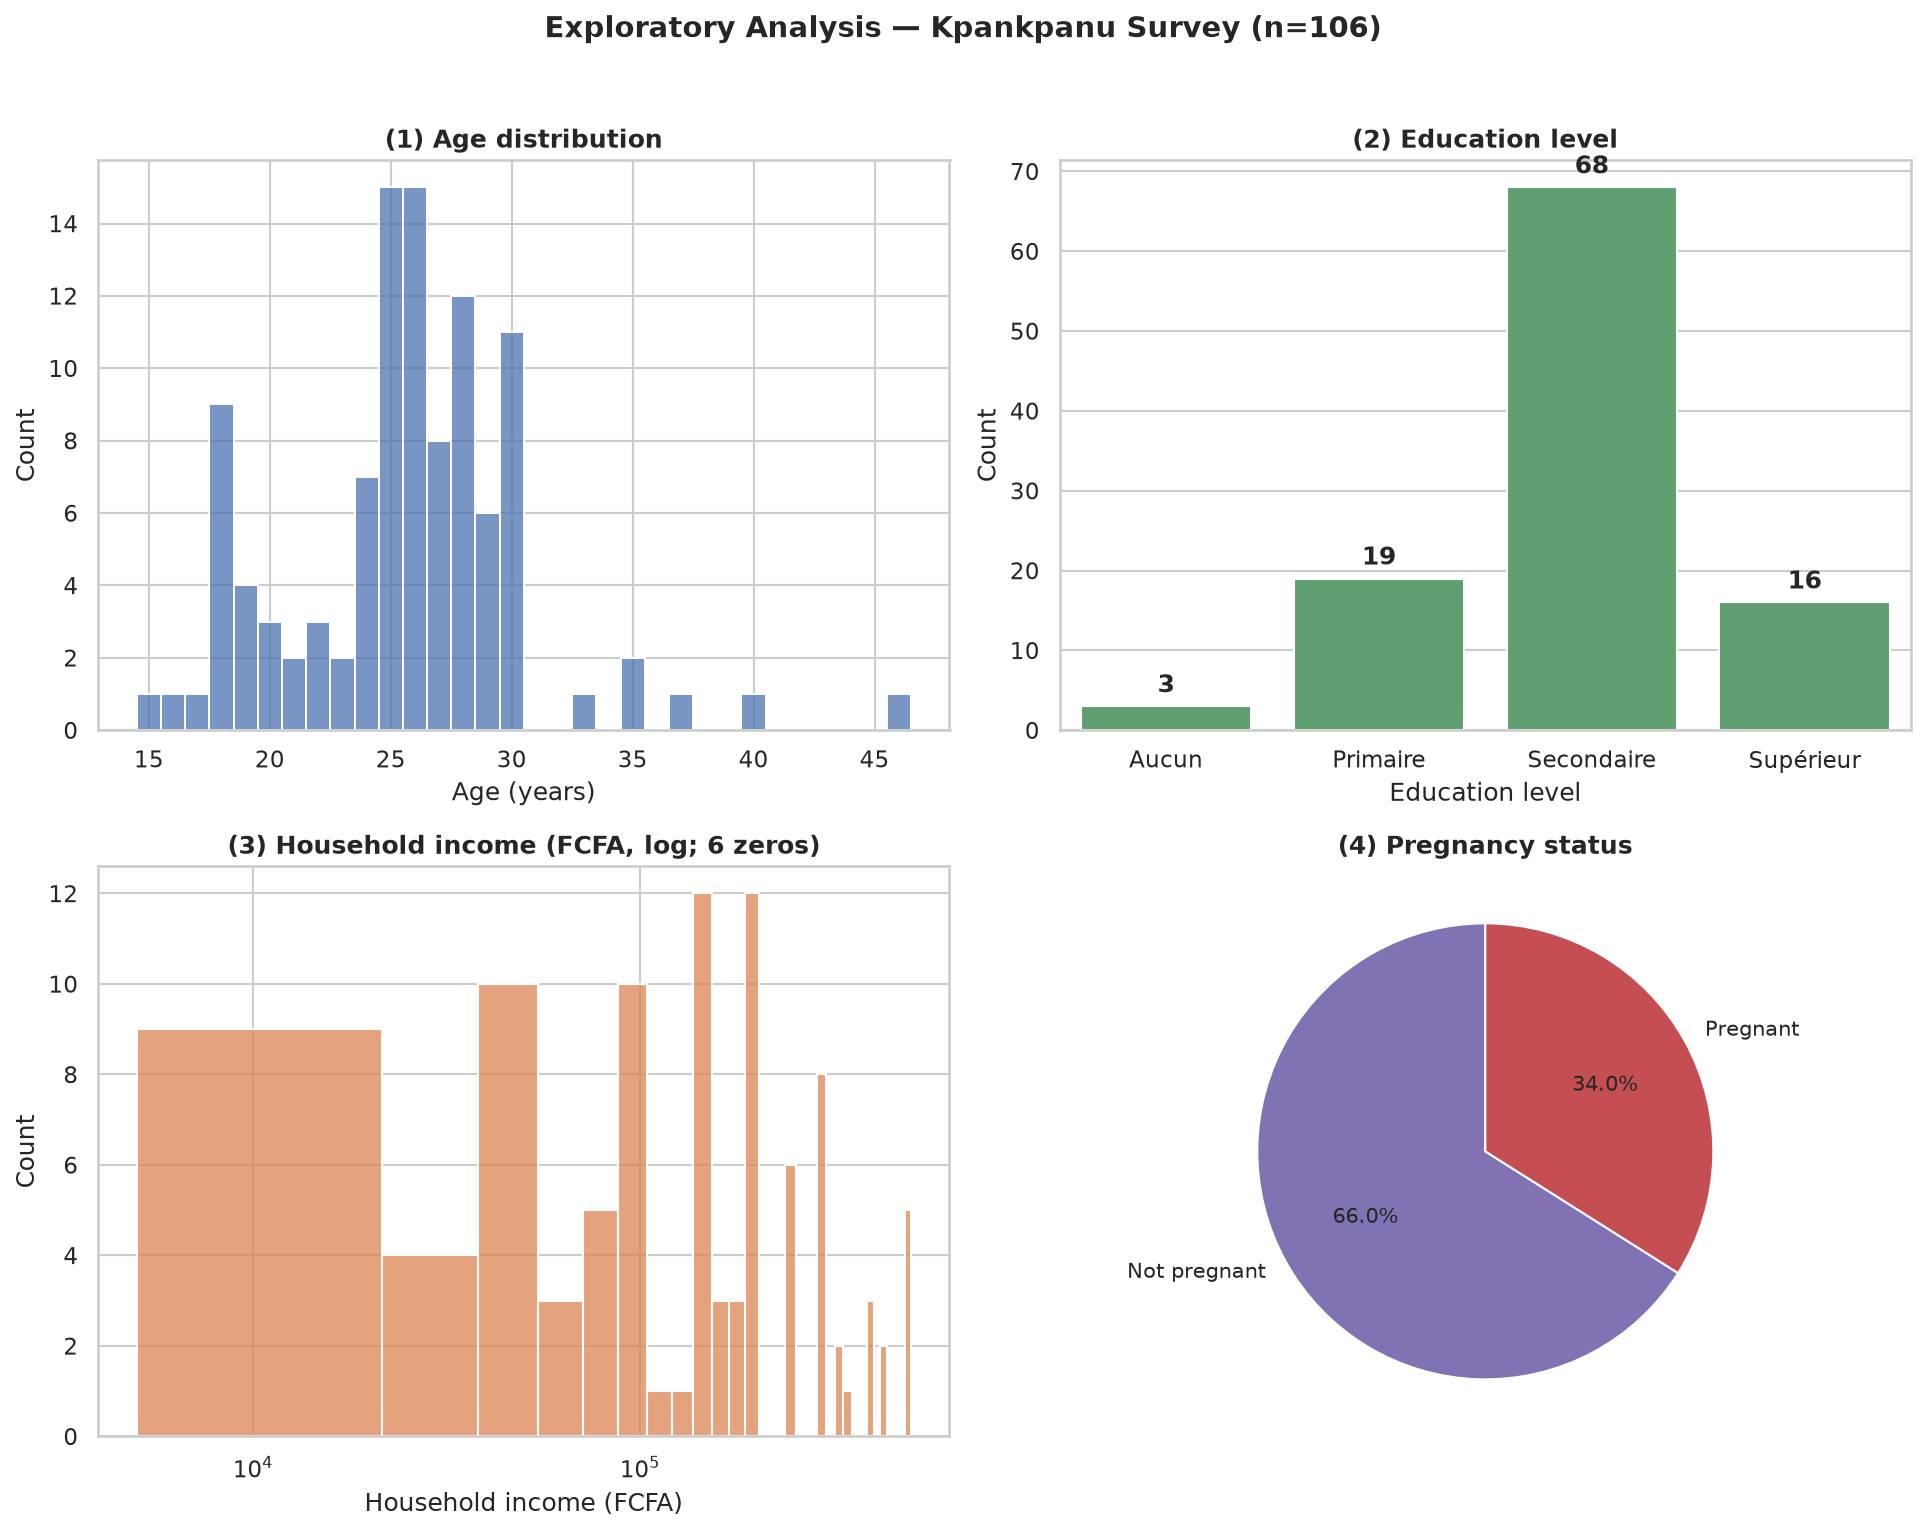

✅ Figure sauvegardée : /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig02_population_profile.png


In [5]:
sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
fig.suptitle("Exploratory Analysis — Kpankpanu Survey (n=106)",
             fontsize=14, fontweight="bold", y=1.02)

# (1) Age
ax = axes[0, 0]
sns.histplot(df["age"], bins=range(int(df["age"].min()), int(df["age"].max()) + 2),
             discrete=True, color="#4C72B0", edgecolor="white", ax=ax)
ax.set_title("(1) Age distribution", fontsize=12, fontweight="bold")
ax.set_xlabel("Age (years)"); ax.set_ylabel("Count")

# (2) Education
ax = axes[0, 1]
edu_order = ["Aucun", "Primaire", "Secondaire", "Supérieur"]
edu_counts = df["education"].value_counts().reindex(edu_order).fillna(0)
sns.barplot(x=edu_counts.index, y=edu_counts.values, color="#55A868", ax=ax)
ax.set_title("(2) Education level", fontsize=12, fontweight="bold")
ax.set_xlabel("Education level"); ax.set_ylabel("Count")
for i, v in enumerate(edu_counts.values):
    ax.text(i, v + 1, str(int(v)), ha="center", va="bottom", fontweight="bold")

# (3) Household income (log)
ax = axes[1, 0]
income_pos = df.loc[df["household_income"] > 0, "household_income"]
n_zero = int((df["household_income"] == 0).sum())
sns.histplot(income_pos, bins=30, color="#DD8452", edgecolor="white", ax=ax)
ax.set_xscale("log")
ax.set_title(f"(3) Household income (FCFA, log; {n_zero} zeros)",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Household income (FCFA)"); ax.set_ylabel("Count")

# (4) Pregnancy
ax = axes[1, 1]
preg_counts = df["is_pregnant"].value_counts().rename({0: "Not pregnant", 1: "Pregnant"})
ax.pie(preg_counts.values, labels=preg_counts.index,
       colors=["#8172B3", "#C44E52"], autopct="%1.1f%%",
       startangle=90, textprops={"fontsize": 10})
ax.set_title("(4) Pregnancy status", fontsize=12, fontweight="bold")

plt.tight_layout()
show_fig(fig, "fig02_population_profile.png")

## Interprètation des Graphiques
L'analyse du profil des 106 femmes interrogées révèle plusieurs caractéristiques clés pour notre étude sur l'adoption du Kpankpanu :

1. **Une population jeune** : La majorité des femmes ont entre 20 et 30 ans, avec un pic marqué à 25 ans. Cela correspond parfaitement à la cible des femmes en âge de procréer, période critique pour la lutte contre la malnutrition infantile.
2. **Un niveau d'éducation moyen** : 68 femmes (soit 64 %) ont atteint le niveau secondaire, et 16 ont un niveau supérieur. Seules 3 n'ont reçu aucune instruction. Ce niveau d'éducation relativement élevé est un atout majeur : il facilitera la réceptivité aux campagnes de sensibilisation nutritionnelle.
3. **De fortes disparités de revenus** : L'échelle logarithmique met en évidence une très grande inégalité économique au sein de l'échantillon. Les revenus s'étalent de 0 FCFA à plus de 100 000 FCFA. La présence de 6 ménages déclarant un revenu de 0 FCFA confirme la nécessité de notre indicateur `is_financially_dependent`. Cette hétérogénéité suggère que le prix devra être adapté à différents segments.
**Pourquoi avoir utilisé l'échelle logarithmique pour exprimer cette variable ?**
L'échelle logarithmique compresse les grands chiffres. Elle permet de "dézoomer" sur les riches pour qu'on puisse voir correctement la répartition des pauvres. C'est un outil indispensable en Data Science pour les variables de revenus.
5. **Une double cible** : 34 % des femmes sont actuellement enceintes. Les 66 % restantes sont des mères d'enfants de moins de 5 ans. Cette répartition montre que le Kpankpanu s'adresse à la fois à des futures mères (prévention) et à des mères d'enfants en bas âge (traitement de la malnutrition)

## Axe 2 — Le paradoxe d'acceptabilité

Nous cherchons ici à analyser le Gap entre l'intention d'achat et le prix auxquel les femmes sont prêtes à se procurer le produit par rapport au prix du kilogramme qui est de 2000 fcfa.
Voici notre petit plan d'implémentation
1. Le paradoxe de base (Le taux d'intention)

On affiche le pourcentage de femmes qui ont répondu "Oui" à l'intention d'achat.

    Graphique : Un barplot simple de buy_intent (0 = Non, 1 = Oui), avec les pourcentages affichés au-dessus des barres.

2. Le mur du prix (La distribution du prix acceptable)

On affiche ce que les femmes sont prêtes à payer, et on trace une ligne rouge à 1 500 FCFA (le prix du marché).

    Graphique : Un histogramme de ideal_price avec une ligne verticale (axvline) à 1500. On verra visuellement si la majorité des barres se trouvent à gauche (en dessous du prix) ou à droite.

3. Le profil de ceux qui veulent acheter (Croisement)

On regarde si le revenu du ménage influence l'intention d'achat.

    Graphique : Un boxplot comparant le revenu du ménage (household_income en échelle log) pour celles qui veulent acheter (1) et celles qui ne veulent pas (0).

**Système de prompt pour OPENCODE**

"Génère une figure Matplotlib/Seaborn en 2 x 2 (2 graphiques sur la première ligne, 1 sur la deuxième, 4ᵉ vide) pour analyser le paradoxe de l'acceptabilité de mon projet.

- Sous-graphique 1 (Gauche) : Un barplot de la variable buy_intent (0=Non, 1=Oui). Ajoute le nombre exact et le pourcentage au-dessus de chaque barre.*

- Sous-graphique 2 (Milieu) : Un histogramme de ideal_price. Ajoute une ligne verticale rouge pointillée à 1500 FCFA annotée 'Market Price (~1500 FCFA)'. Calcule le pourcentage de femmes dont le prix acceptable est inférieur à 1500 FCFA et affiche-le dans le titre.*

- Sous-graphique 3 (Droite) : Un boxplot croisant buy_intent (en x) et household_income (en y, avec échelle logarithmique via ax.set_yscale('log')).*

**Instructions globales** :
        Ajoute un titre principal global avec fig.suptitle().
        Titres en anglais pour chaque sous-graphique.
        Commentaires bilingues (EN/FR) dans le code.
Utilise plutôt IPython combiné à matplotlib pour l'affichage du graphique à cause des problèmes liés au backend inline de jupyter

Text(0.5, 1.02, 'Acceptability Paradox — Kpankpanu Survey (n=106)')

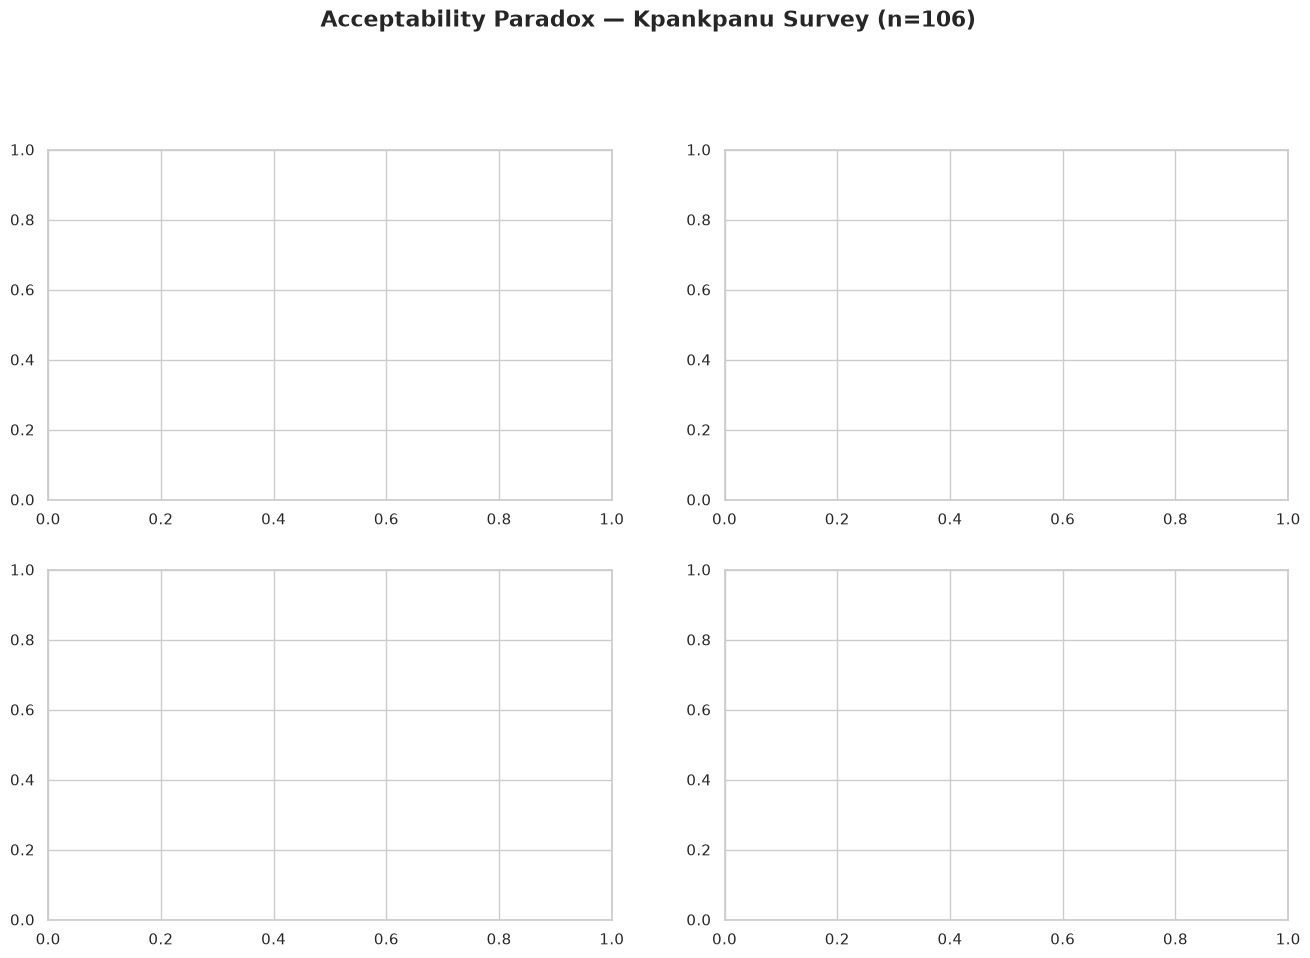

In [6]:
# EN: Validate required columns and values
# FR: Validation des colonnes requises et des valeurs
required_cols = ["buy_intent", "ideal_price", "household_income"]
missing = [c for c in required_cols if c not in df.columns]
assert not missing, f"EN: Missing columns: {missing}\nFR: Colonnes manquantes : {missing}"
assert df["buy_intent"].isin([0, 1]).all(), "EN: buy_intent must be binary 0/1\nFR: buy_intent doit être binaire 0/1"
assert df["household_income"].notna().all(), "EN: household_income contains NaN\nFR: household_income contient des NaN"

# EN: Prepare output directory at project root
# FR: Préparation du répertoire de sortie à la racine du projet
fig_dir = project_root / "reports" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# EN: Set style
# FR: Style graphique
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

# EN: Create 2x2 figure (3 subplots used, bottom-right empty)
# FR: Création figure 2x2 (3 sous-graphiques utilisés, bas-droit vide)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Acceptability Paradox — Kpankpanu Survey (n=106)",
             fontsize=16, fontweight="bold", y=1.02)

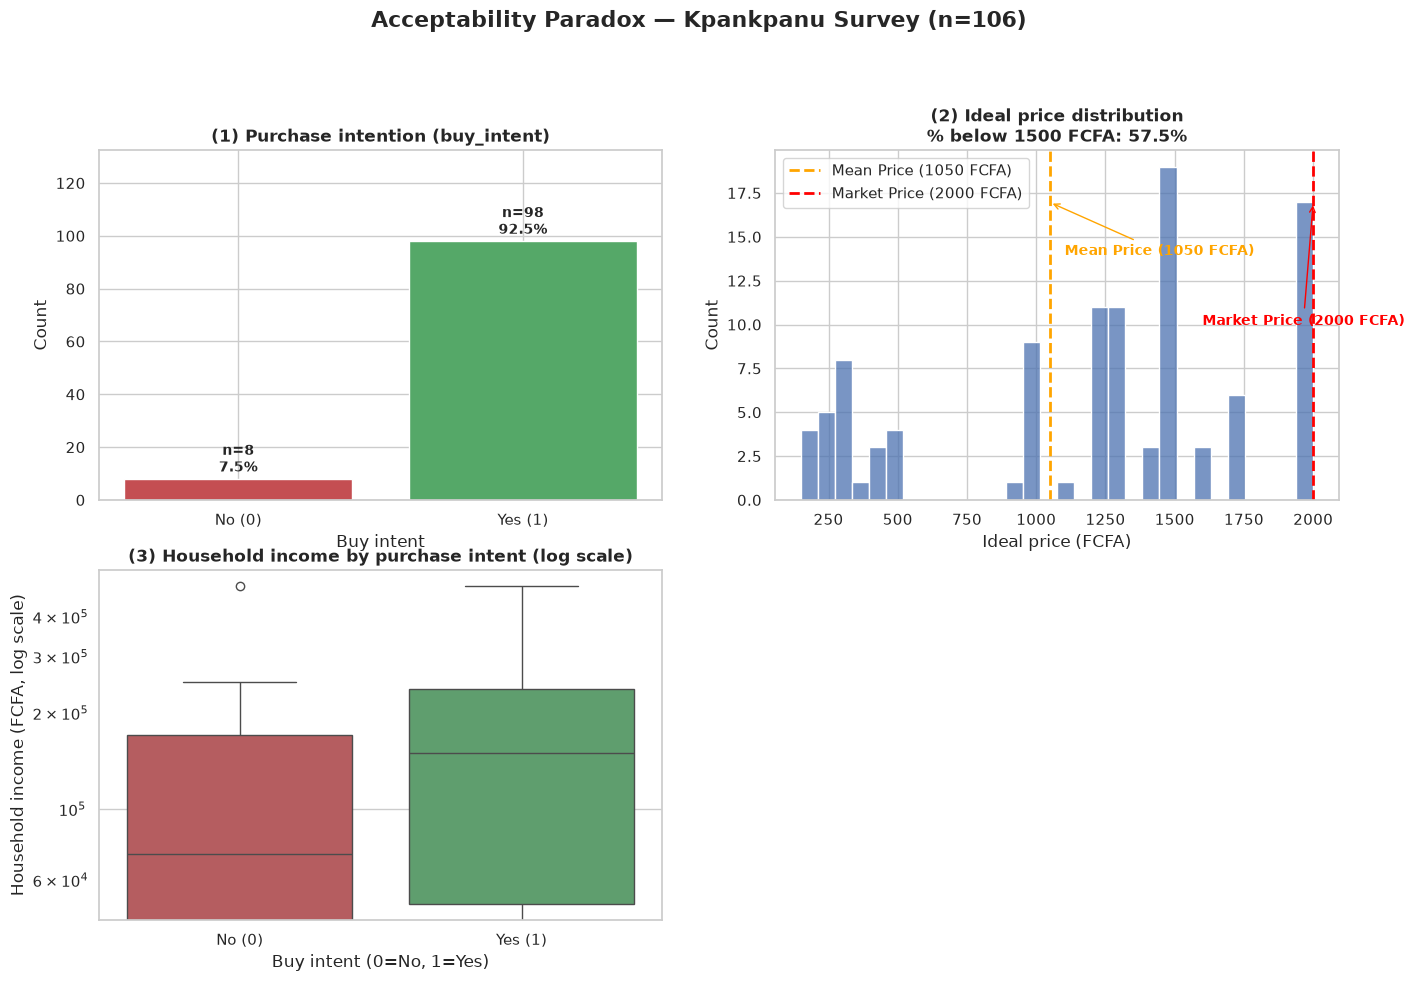

EN: Figure saved to /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig03_acceptability_paradox.png
FR: Figure enregistrée dans /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig03_acceptability_paradox.png


<Figure size 1000x600 with 0 Axes>

In [7]:
# ------------------------------------------------------------------
# (1) Top-left: Barplot of buy_intent with count and percentage
# ------------------------------------------------------------------
ax = axes[0, 0]
buy_counts = df["buy_intent"].value_counts().sort_index()
buy_labels = ["No (0)", "Yes (1)"]
total = len(df)
bars = ax.bar(buy_labels, buy_counts.values, color=["#C44E52", "#55A868"], edgecolor="white")
for bar, count in zip(bars, buy_counts.values):
    pct = 100 * count / total
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            f"n={count}\n{pct:.1f}%", ha="center", va="bottom", fontweight="bold", fontsize=10)
ax.set_title("(1) Purchase intention (buy_intent)", fontsize=12, fontweight="bold")
ax.set_xlabel("Buy intent")
ax.set_ylabel("Count")
ax.set_ylim(0, total * 1.25)

# ------------------------------------------------------------------
# (2) Top-right: Histogram of ideal_price with market price line
# ------------------------------------------------------------------
ax = axes[0, 1]
price_valid = df["ideal_price"].dropna()
n_price_valid = len(price_valid)
pct_below_1500 = 100 * (price_valid < 1500).sum() / n_price_valid if n_price_valid > 0 else 0

mean_price = 1050    # EN: mean acceptable price / FR: prix moyen acceptable
market_price = 2000  # EN: market price per kg / FR: prix du marché par kg

sns.histplot(price_valid, bins=30, color="#4C72B0", edgecolor="white", ax=ax)

# EN: Vertical line for mean acceptable price (orange)
# FR: Ligne verticale pour le prix moyen acceptable (orange)
ax.axvline(mean_price, color="orange", linestyle="--", linewidth=2,
           label=f"Mean Price ({mean_price} FCFA)")

# EN: Vertical line for market price per kg (red)
# FR: Ligne verticale pour le prix du marché par kg (rouge)
ax.axvline(market_price, color="red", linestyle="--", linewidth=2,
           label=f"Market Price ({market_price} FCFA)")

ymax = ax.get_ylim()[1]
ax.annotate(f"Mean Price ({mean_price} FCFA)", xy=(mean_price, ymax * 0.85),
            xytext=(mean_price * 1.05, ymax * 0.70),
            color="orange", fontsize=10, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color="orange"))
ax.annotate(f"Market Price ({market_price} FCFA)", xy=(market_price, ymax * 0.85),
            xytext=(market_price * 0.80, ymax * 0.50),
            color="red", fontsize=10, fontweight="bold",
            arrowprops=dict(arrowstyle="->", color="red"))

ax.set_title(f"(2) Ideal price distribution\n% below 1500 FCFA: {pct_below_1500:.1f}%",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Ideal price (FCFA)")
ax.set_ylabel("Count")
ax.legend()

# ------------------------------------------------------------------
# (3) Bottom-left: Boxplot household_income by buy_intent (log scale y)
# ------------------------------------------------------------------
ax = axes[1, 0]
sns.boxplot(x="buy_intent", y="household_income", data=df,
            hue="buy_intent", palette=["#C44E52", "#55A868"], legend=False, ax=ax)
ax.set_yscale("log")
ax.set_title("(3) Household income by purchase intent (log scale)",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Buy intent (0=No, 1=Yes)")
ax.set_ylabel("Household income (FCFA, log scale)")
ax.set_xticks([0, 1])
ax.set_xticklabels(["No (0)", "Yes (1)"])

# EN: Hide empty bottom-right subplot
# FR: Masquer le sous-graphique vide en bas à droite
fig.delaxes(axes[1, 1])

# EN: Layout, display via IPython, then save
# FR: Mise en page, affichage via IPython, puis sauvegarde
plt.tight_layout()
display(fig)

out_path = fig_dir / "fig03_acceptability_paradox.png"
fig.savefig(out_path, dpi=150, bbox_inches="tight")
plt.close(fig)

# EN: Assertion: figure file was created
# FR: Assertion : le fichier de figure a été créé
assert out_path.is_file(), f"EN: Figure not saved at {out_path}\nFR: Figure non enregistrée à {out_path}"
print(f"EN: Figure saved to {out_path}\nFR: Figure enregistrée dans {out_path}")

## Interprètation des Graphiques 
L'analyse croisée de ces trois indicateurs met en évidence le paradoxe central de notre étude :
1. **Une acceptabilité massive (92,5%)** : Presque toutes les femmes (98/106) déclarent vouloir consommer la farine Kpankpanu. Le désir est là.
2. **Le fossé économique (Say-Do Gap)** : L'analyse de la distribution des prix révèle un écart critique. Alors que le prix réel du marché est fixé à **2000 FCFA/kg**, le prix moyen que les femmes jugent acceptable n'est que de **1050 FCFA**. Plus de la moitié d'entre elles (57,5%) proposent même un prix inférieur à 1500 FCFA. Le produit est donc économiquement inaccessible pour la majorité de la cible.
3. **Un désir indépendant du revenu** : Le boxplot montre que le revenu du ménage ne discrimine pas l'intention d'achat. Les femmes aux revenus les plus modestes veulent autant l'acheter que les plus aisées (la motivation première étant la santé de l'enfant). Le frein n'est donc pas le manque d'envie, mais la capacité financière.

**Conclusion:** L'acceptabilité déclarée ne suffit pas. Pour transformer ces 92,5% d'intentions en achats réels face à un prix de 2000 FCFA, une stratégie de conditionnement s'impose (ex: vendre des sachets de 250g ou 500g à un prix inférieur à 1000 FCFA) pour s'aligner sur le budget réel des ménages.

# AXE 3 — LA BARRIÈRE DU PRIX


Nous avons constaté un écart entre le prix souhaité (~1050 FCFA) et le prix réel (2000 FCFA). L'objectif de cet axe est de vérifier si le prix acceptable est corrélé au revenu du ménage. Autrement dit : est-ce que les femmes les plus riches sont prêtes à payer plus cher, ou bien le prix de 1000 FCFA est-il un plafond psychologique universel, peu importe le revenu ?

### Système de prompt pour OPENCODE
"Génère un nuage de points (scatter plot) avec Seaborn croisant household_income (en abscisse, échelle logarithmique) et ideal_price (en ordonnées). Ajoute une ligne de tendance (régression linéaire) en rouge. Utilise la variable low_price_respondent (0/1) pour colorer les points différemment (ex: gris pour 0, orange pour 1). Affiche le coefficient de corrélation de Spearman dans le titre pour montrer si la relation est forte ou faible. Titre en anglais, commentaires bilingues (EN/FR)"

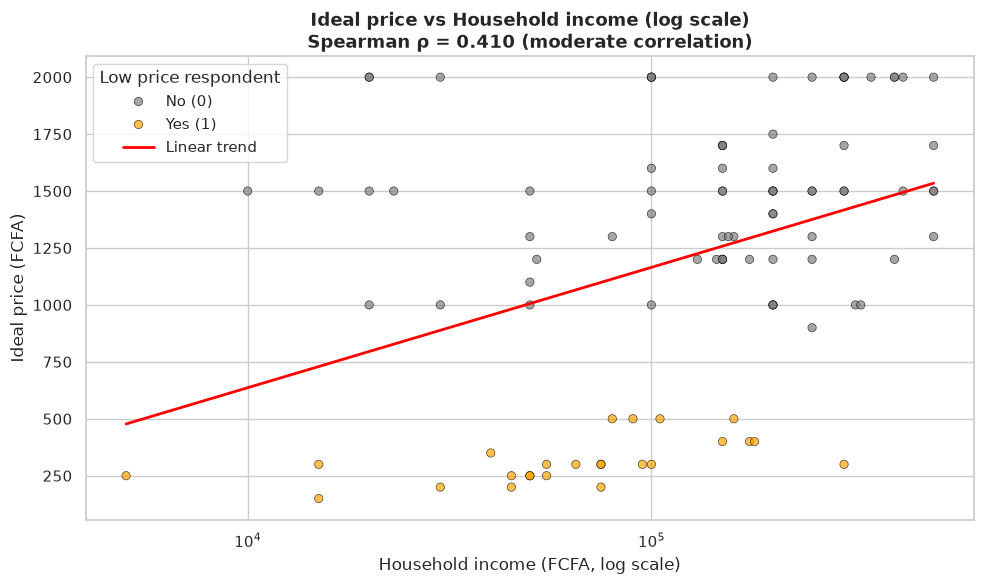

EN: Figure saved to /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig04_scatter_income_price.png
FR: Figure enregistrée dans /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig04_scatter_income_price.png
EN: Rows used: 100 / 106
FR: Lignes utilisées : 100 / 106
EN: Spearman ρ = 0.4104 (moderate)
FR: Rho de Spearman = 0.4104 (moderate)


In [4]:
# EN: Validate required columns
# FR: Validation des colonnes requises
required_cols = ["household_income", "ideal_price", "low_price_respondent"]
missing = [c for c in required_cols if c not in df.columns]
assert not missing, f"EN: Missing columns: {missing}\nFR: Colonnes manquantes : {missing}"

# EN: Filter rows with valid ideal_price and positive household_income (log scale cannot handle 0)
# FR: Filtrage des lignes avec ideal_price valide et revenu ménage > 0 (échelle log ne gère pas le 0)
df_plot = df.loc[df["ideal_price"].notna() & (df["household_income"] > 0)].copy()
assert len(df_plot) > 0, "EN: No valid rows for scatter plot\nFR: Aucune ligne valide pour le nuage de points"

# EN: Spearman correlation and strength interpretation
# FR: Corrélation de Spearman et interprétation de la force
rho = df_plot["household_income"].corr(df_plot["ideal_price"], method="spearman")
if abs(rho) >= 0.7:
    strength = "strong"
elif abs(rho) >= 0.4:
    strength = "moderate"
else:
    strength = "weak"

# EN: Prepare figure
# FR: Préparation de la figure
fig, ax = plt.subplots(figsize=(10, 6))

# EN: Scatter plot colored by low_price_respondent (0=gray, 1=orange)
# FR: Nuage de points coloré par low_price_respondent (0=gris, 1=orange)
sns.scatterplot(
    data=df_plot,
    x="household_income",
    y="ideal_price",
    hue="low_price_respondent",
    palette={0: "gray", 1: "orange"},
    alpha=0.7,
    edgecolor="black",
    linewidth=0.5,
    ax=ax,
)

# EN: Linear regression trend line on log10(X) — red
# FR: Ligne de tendance régression linéaire sur log10(X) — rouge
x_log = np.log10(df_plot["household_income"])
y = df_plot["ideal_price"].values
m, b = np.polyfit(x_log, y, 1)
x_vals = np.logspace(
    np.log10(df_plot["household_income"].min()),
    np.log10(df_plot["household_income"].max()),
    100,
)
y_vals = m * np.log10(x_vals) + b
ax.plot(x_vals, y_vals, color="red", linewidth=2, label="Linear trend")

# EN: Log scale on X axis
# FR: Échelle logarithmique sur l'axe X
ax.set_xscale("log")

# EN: Labels and title with Spearman coefficient
# FR: Libellés et titre avec coefficient de Spearman
ax.set_title(
    f"Ideal price vs Household income (log scale)\nSpearman ρ = {rho:.3f} ({strength} correlation)",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Household income (FCFA, log scale)")
ax.set_ylabel("Ideal price (FCFA)")

# EN: Legend title and labels
# FR: Titre et libellés de la légende
legend = ax.legend(title="Low price respondent")
for text in legend.get_texts():
    if text.get_text() == "0":
        text.set_text("No (0)")
    elif text.get_text() == "1":
        text.set_text("Yes (1)")

# EN: Layout, display via IPython, then save
# FR: Mise en page, affichage via IPython, puis sauvegarde
plt.tight_layout()
display(fig)

out_path = project_root / "reports" / "figures" / "fig04_scatter_income_price.png"
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out_path, dpi=150, bbox_inches="tight")
plt.close(fig)

# EN: Assertion: figure file was created
# FR: Assertion : le fichier de figure a été créé
assert out_path.is_file(), f"EN: Figure not saved at {out_path}\nFR: Figure non enregistrée à {out_path}"
print(f"EN: Figure saved to {out_path}\nFR: Figure enregistrée dans {out_path}")
print(f"EN: Rows used: {len(df_plot)} / {len(df)}\nFR: Lignes utilisées : {len(df_plot)} / {len(df)}")
print(f"EN: Spearman ρ = {rho:.4f} ({strength})\nFR: Rho de Spearman = {rho:.4f} ({strength})")

Le graphique met en évidence une **corrélation positive modérée (Spearman ρ = 0.41)** entre le revenu du ménage et le prix acceptable. Trois enseignements majeurs se dégagent :
1. **Le revenu influence le prix** : La ligne de tendance (rouge) montre clairement que les ménages les plus aisés sont prêts à payer plus cher (jusqu'à 2000 FCFA).
2. **Un plafond psychologique à 2000 FCFA** : Même pour les revenus les plus élevés (au-delà de \(10^5\) FCFA), les points plafonnent exactement à 2000 FCFA. Cela signifie que le prix réel du marché est perçu comme la limite absolue à ne pas dépasser, même par les plus riches.
3. **Le paradoxe des prix bas (Points orange)** : Les femmes ayant déclaré un prix très bas (≤ 500 FCFA) sont réparties sur **tous les niveaux de revenus**. Il ne s'agit donc pas uniquement de femmes pauvres, mais probablement d'une incompréhension du format (confusion avec le prix d'une petite mesure) ou d'une stratégie de négociation. 
4. **La réalité des bas revenus** : Pour les ménages à faible revenu (autour de \(10^4\)), le prix idéal tourne autour de 1000 FCFA. Le produit à 2000 FCFA y est donc inaccessible.

**Conclusion:** Une stratégie de prix unique à 2000 FCFA exclura la majorité des ménages à faibles revenus. Il faut proposer un conditionnement adapté (ex: sachets de 500g à 1000 FCFA) pour pénétrer le marché des bas revenus, tout en maintenant un format 1kg à 2000 FCFA pour les ménages aisés.

# AXE 4 : lE BÉNÉFICE PERÇU POUR L'ENFANT : MOTEUR D'ACHAT OU SIMPLE INTENTION

Puisque notre population cible est composée de mères et de futures mères, nous testons l'hypothèse suivante : est-ce que le fait de croire que la farine est bonne pour la santé de l'enfant (perceived_child_benefit) est un moteur direct de l'intention d'achat ? Autrement dit, les femmes qui croient au bénéfice nutritionnel pour leur enfant sont-elles plus enclines à vouloir l'acheter pour elles-mêmes ?"
    (Note : on ne garde que les femmes ayant au moins un enfant de moins de 5 ans, soit has_child_under_5 == 1, pour éviter les NaN de la logique de saut)

### Système de prompt pour OPENCODE
Filtre le DataFrame pour ne garder que les mères d'enfants de moins de 5 ans (df['has_child_under_5'] == 1). Génère un barplot groupé (grouped barplot) avec Seaborn croisant perceived_child_benefit (en abscisse, 0=Non, 1=Oui) et buy_intent (en couleur/teinte, 0=Non, 1=Oui). Ajoute les pourcentages au-dessus des barres. Ajoute un titre clair en anglais expliquant l'impact du bénéfice perçu sur l'intention d'achat. Commentaires bilingues.

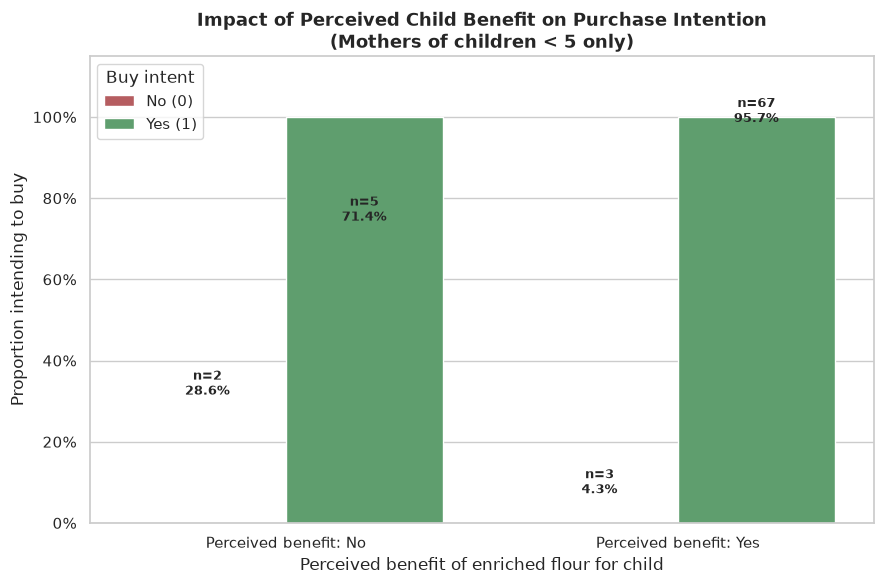

EN: Figure saved to /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig05_grouped_bar_benefit_buyintent.png
FR: Figure enregistrée dans /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig05_grouped_bar_benefit_buyintent.png
EN: Mothers of <5 used: 77
FR: Mères d'enfants <5 utilisées : 77


In [7]:
# EN: Validate required columns exist
# FR: Validation de l'existence des colonnes requises
required_cols = ["has_child_under_5", "perceived_child_benefit", "buy_intent"]
missing = [c for c in required_cols if c not in df.columns]
assert not missing, f"EN: Missing columns: {missing}\nFR: Colonnes manquantes : {missing}"
assert df["has_child_under_5"].isin([0, 1]).all(), "EN: has_child_under_5 must be binary\nFR: has_child_under_5 doit être binaire"
assert df["buy_intent"].isin([0, 1]).all(), "EN: buy_intent must be binary\nFR: buy_intent doit être binaire"
# EN: perceived_child_benefit may contain NaN (skip logic: no child < 5) — allowed
# FR: perceived_child_benefit peut contenir des NaN (logique de saut: pas d'enfant <5) — autorisé
pcb_vals = df["perceived_child_benefit"].dropna().unique()
assert set(pcb_vals) <= {0, 1}, f"EN: perceived_child_benefit has invalid values: {pcb_vals}\nFR: perceived_child_benefit a des valeurs invalides : {pcb_vals}"

# EN: Filter to mothers of children under 5 AND with non-missing perceived_child_benefit
# FR: Filtrage sur mères d'enfants <5 ET avec perceived_child_benefit non manquant
df_mothers = df.loc[(df["has_child_under_5"] == 1) & df["perceived_child_benefit"].notna()].copy()
assert len(df_mothers) > 0, "EN: No valid mothers of <5 found\nFR: Aucune mère d'enfant <5 valide trouvée"

# EN: Compute counts and row percentages per perceived_child_benefit group
# FR: Calcul des effectifs et pourcentages ligne par groupe de perceived_child_benefit
ct = pd.crosstab(df_mothers["perceived_child_benefit"], df_mothers["buy_intent"])
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

# EN: Prepare figure
# FR: Préparation de la figure
fig, ax = plt.subplots(figsize=(9, 6))

# EN: Grouped barplot: x = perceived_child_benefit, hue = buy_intent
# FR: Barplot groupé : x = perceived_child_benefit, teinte = buy_intent
sns.barplot(
    data=df_mothers,
    x="perceived_child_benefit",
    y="buy_intent",
    hue="buy_intent",
    palette={0: "#C44E52", 1: "#55A868"},
    estimator=np.mean,
    errorbar=None,
    ax=ax,
)

# EN: Add percentages above each bar (row %)
# FR: Ajout des pourcentages au-dessus de chaque barre (pourcentage de ligne)
x_labels_order = [0, 1]
for i, x_val in enumerate(x_labels_order):
    for j, hue_val in enumerate([0, 1]):
        if x_val not in ct.index or hue_val not in ct.columns:
            continue
        count = int(ct.loc[x_val, hue_val])
        pct = ct_pct.loc[x_val, hue_val]
        bar_x = i + (j - 0.5) * 0.4
        ax.text(
            bar_x,
            pct / 100 + 0.02,
            f"n={count}\n{pct:.1f}%",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
        )

ax.set_xticks([0, 1])
ax.set_xticklabels(["Perceived benefit: No", "Perceived benefit: Yes"])
ax.set_title(
    "Impact of Perceived Child Benefit on Purchase Intention\n(Mothers of children < 5 only)",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Perceived benefit of enriched flour for child")
ax.set_ylabel("Proportion intending to buy")
ax.set_ylim(0, 1.15)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(["0%", "20%", "40%", "60%", "80%", "100%"])

# EN: Legend labels
# FR: Libellés de la légende
legend = ax.legend(title="Buy intent")
for text in legend.get_texts():
    if text.get_text() == "0":
        text.set_text("No (0)")
    elif text.get_text() == "1":
        text.set_text("Yes (1)")

# EN: Layout, display via IPython, then save
# FR: Mise en page, affichage via IPython, puis sauvegarde
plt.tight_layout()
display(fig)

out_path = project_root / "reports" / "figures" / "fig05_grouped_bar_benefit_buyintent.png"
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out_path, dpi=150, bbox_inches="tight")
plt.close(fig)

# EN: Assertions
# FR: Assertions
assert out_path.is_file(), f"EN: Figure not saved at {out_path}\nFR: Figure non enregistrée à {out_path}"
print(f"EN: Figure saved to {out_path}\nFR: Figure enregistrée dans {out_path}")
print(f"EN: Mothers of <5 used: {len(df_mothers)}\nFR: Mères d'enfants <5 utilisées : {len(df_mothers)}")

Le graphique est fait mais ce n'est pas interprètable. Pour le groupe de gauche ("Perceived benefit: No"), la barre verte monte jusqu'à 100 %, mais l'étiquette indique 71.4 %. Et la barre rouge (n=2, 28.6 %) a complètement disparu. Même problème au niveau du second groupe qui affiche un pourcentage de 95,7% pour les femmes qui pensent que la farine pourrait être bénéfique pour leur enfant et qui ont l'intention de l'acheter pour elles-mêmes. 

Nous allons fournir une consigne à notre agent pour corriger ce bug 
### Système de prompt correctif OPENCODE
Le graphique précédent a un bug d'affichage (barres manquantes, hauteurs incohérentes). Refais-le en utilisant pd.crosstab avec normalize='index' pour calculer les proportions. Trace le résultat sous forme de diagramme en barres empilées (stacked bar chart) avec Pandas (.plot(kind='bar', stacked=True)), en utilisant les couleurs rouge (No) et verte (Yes). Ajoute les pourcentages au centre de chaque segment. Titre en anglais

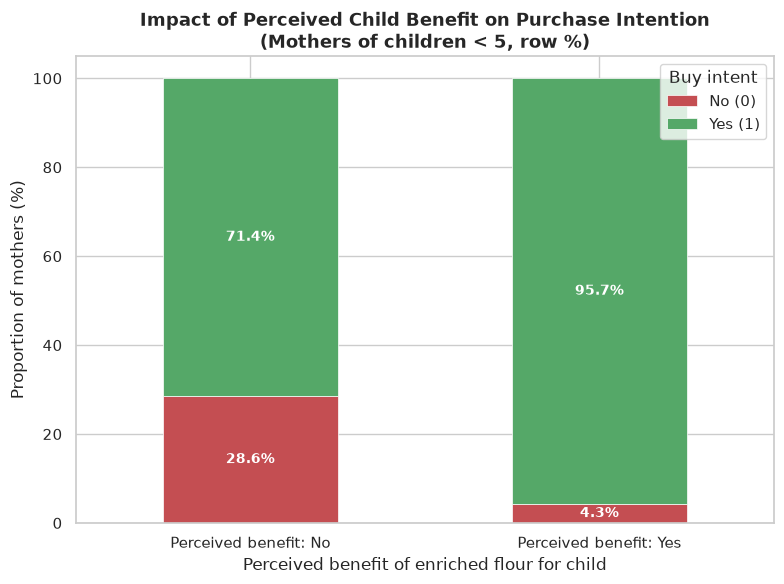

EN: Figure saved to /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig05_stacked_bar_benefit_buyintent.png
FR: Figure enregistrée dans /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig05_stacked_bar_benefit_buyintent.png
EN: Mothers of <5 used: 77
FR: Mères d'enfants <5 utilisées : 77


In [8]:
# EN: Validate required columns exist
# FR: Validation de l'existence des colonnes requises
required_cols = ["has_child_under_5", "perceived_child_benefit", "buy_intent"]
missing = [c for c in required_cols if c not in df.columns]
assert not missing, f"EN: Missing columns: {missing}\nFR: Colonnes manquantes : {missing}"
assert df["has_child_under_5"].isin([0, 1]).all(), "EN: has_child_under_5 must be binary\nFR: has_child_under_5 doit être binaire"
assert df["buy_intent"].isin([0, 1]).all(), "EN: buy_intent must be binary\nFR: buy_intent doit être binaire"

# EN: Filter to mothers of children under 5 with non-missing perceived_child_benefit
# FR: Filtrage sur mères d'enfants <5 ET perceived_child_benefit non manquant
df_mothers = df.loc[(df["has_child_under_5"] == 1) & df["perceived_child_benefit"].notna()].copy()
assert len(df_mothers) > 0, "EN: No valid mothers of <5 found\nFR: Aucune mère d'enfant <5 valide trouvée"

# EN: Crosstab with row normalization (percentages per perceived_child_benefit group)
# FR: Crosstab avec normalisation ligne (pourcentages par groupe de perceived_child_benefit)
ct = pd.crosstab(
    df_mothers["perceived_child_benefit"],
    df_mothers["buy_intent"],
    normalize="index",
) * 100

# EN: Ensure both buy_intent columns (0 and 1) exist, fill missing with 0
# FR: S'assurer que les deux colonnes buy_intent (0 et 1) existent, combler les manquantes avec 0
for col in [0, 1]:
    if col not in ct.columns:
        ct[col] = 0.0
ct = ct[[0, 1]]  # EN: column order: No (0) then Yes (1) / FR: ordre des colonnes : Non (0) puis Oui (1)

# EN: Ensure both x-axis categories (0 and 1) exist
# FR: S'assurer que les deux catégories de l'axe x (0 et 1) existent
for idx in [0, 1]:
    if idx not in ct.index:
        ct.loc[idx] = 0.0
ct = ct.sort_index()

# EN: Prepare figure
# FR: Préparation de la figure
fig, ax = plt.subplots(figsize=(8, 6))

# EN: Stacked bar plot — red for buy_intent=0 (No), green for buy_intent=1 (Yes)
# FR: Diagramme en barres empilées — rouge pour buy_intent=0 (Non), vert pour buy_intent=1 (Oui)
ct.plot(
    kind="bar",
    stacked=True,
    color={0: "#C44E52", 1: "#55A868"},
    edgecolor="white",
    linewidth=0.5,
    ax=ax,
)

# EN: Add percentages at the center of each segment
# FR: Ajout des pourcentages au centre de chaque segment
for i, x_val in enumerate(ct.index):
    bottom = 0
    for hue_val in [0, 1]:
        pct = ct.loc[x_val, hue_val]
        if pct > 0:
            ax.text(
                i,
                bottom + pct / 2,
                f"{pct:.1f}%",
                ha="center",
                va="center",
                color="white",
                fontsize=10,
                fontweight="bold",
            )
        bottom += pct

# EN: Labels and title in English
# FR: Libellés et titre en anglais
ax.set_title(
    "Impact of Perceived Child Benefit on Purchase Intention\n(Mothers of children < 5, row %)",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Perceived benefit of enriched flour for child")
ax.set_ylabel("Proportion of mothers (%)")
ax.set_xticks(range(len(ct.index)))
ax.set_xticklabels(["Perceived benefit: No", "Perceived benefit: Yes"], rotation=0)
ax.set_ylim(0, 105)

# EN: Legend labels
# FR: Libellés de la légende
legend = ax.legend(title="Buy intent", loc="upper right")
for text in legend.get_texts():
    if text.get_text() == "0":
        text.set_text("No (0)")
    elif text.get_text() == "1":
        text.set_text("Yes (1)")

# EN: Layout, display via IPython, then save
# FR: Mise en page, affichage via IPython, puis sauvegarde
plt.tight_layout()
display(fig)

out_path = project_root / "reports" / "figures" / "fig05_stacked_bar_benefit_buyintent.png"
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out_path, dpi=150, bbox_inches="tight")
plt.close(fig)

# EN: Assertions
# FR: Assertions
assert out_path.is_file(), f"EN: Figure not saved at {out_path}\nFR: Figure non enregistrée à {out_path}"
print(f"EN: Figure saved to {out_path}\nFR: Figure enregistrée dans {out_path}")
print(f"EN: Mothers of <5 used: {len(df_mothers)}\nFR: Mères d'enfants <5 utilisées : {len(df_mothers)}")

Voilà, nous avons maintenant un graphique interprètable.
**Interprètation**
L'analyse de l'impact du bénéfice perçu pour l'enfant (réalisée uniquement sur les 77 mères d'enfants de moins de 5 ans) révèle un comportement très intéressant :
1. **Un moteur d'achat quasi-unanime** : Lorsqu'une mère croit que la farine Kpankpanu est bénéfique pour la santé de son enfant ("Perceived benefit: Yes"), l'intention d'achat atteint **95,7 %** (seules 4,3 % refusent).
2. **Une intention de base élevée** : Même parmi les rares mères qui ne perçoivent pas le bénéfice nutritionnel ("Perceived benefit: No"), l'intention d'achat reste forte à **71,4 %**. Cela montre que le produit bénéficie d'un capital de confiance général (ou que l'intention déclarée est biaisée à la hausse).
3. **L'écart qui compte** : Le fait de croire au bénéfice pour l'enfant fait passer le taux d'adhésion de 71,4 % à 95,7 %. La valeur nutritionnelle perçue est donc un **levier de conversion puissant**.

**Conclusion:** Le produit est perçu comme sain et crédible par les mères. La communication marketing n'a pas besoin de les convaincre de l'utilité du produit (elles sont déjà convaincues). La stratégie doit se concentrer sur le prix et l'accessibilité financière pour concrétiser cette immense intention d'achat.

# AXE 5: CORRÉLATIONS ENTRE LES VARIABLES

Pour clôturer cette analyse exploratoire et préparer le Machine Learning, nous dressons une carte globale des corrélations (matrice de Spearman) entre toutes les variables numériques. Cela nous permettra de repérer visuellement les relations fortes (positives ou négatives) et d'éviter la multicolinéarité (deux variables qui disent exactement la même chose) avant d'entraîner nos modèles prédictifs.

### Système de prompt OPENCODE
Génère une heatmap (carte de chaleur) de corrélation de Spearman avec Seaborn pour les colonnes suivantes : age, income, household_income, ideal_price, buy_intent, perceived_child_benefit, num_children, is_financially_dependent. Masque la moitié supérieure de la matrice (triangle supérieur) pour ne garder que le triangle inférieur. Affiche les coefficients de corrélation annotés avec 2 décimales. Les corrélations fortes doivent ressortir visuellement (utilise une palette de couleurs divergente comme 'coolwarm'). Titre en anglais, commentaires bilingues

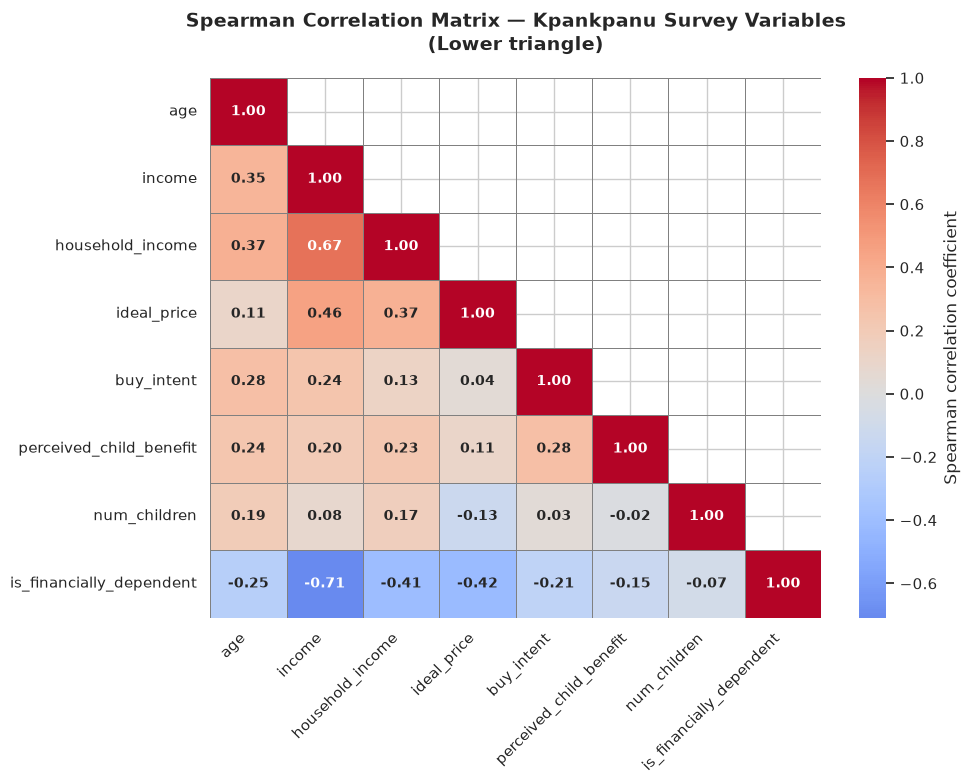

EN: Figure saved to /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig06_spearman_heatmap.png
FR: Figure enregistrée dans /home/adjaho/Documents/CANDIDATURE POSTE STAGIAIRE/data-analysis-kpankpanu-benin/reports/figures/fig06_spearman_heatmap.png
EN: Correlation columns (8): ['age', 'income', 'household_income', 'ideal_price', 'buy_intent', 'perceived_child_benefit', 'num_children', 'is_financially_dependent']
FR: Colonnes de corrélation (8) : ['age', 'income', 'household_income', 'ideal_price', 'buy_intent', 'perceived_child_benefit', 'num_children', 'is_financially_dependent']


In [9]:
# EN: Validate required columns exist
# FR: Validation de l'existence des colonnes requises
corr_cols = [
    "age",
    "income",
    "household_income",
    "ideal_price",
    "buy_intent",
    "perceived_child_benefit",
    "num_children",
    "is_financially_dependent",
]
missing = [c for c in corr_cols if c not in df.columns]
assert not missing, f"EN: Missing columns: {missing}\nFR: Colonnes manquantes : {missing}"

# EN: Compute Spearman correlation matrix (pairwise handling of NaN)
# FR: Calcul de la matrice de corrélation de Spearman (gestion paire par paire des NaN)
corr = df[corr_cols].corr(method="spearman")

# EN: Create mask for upper triangle (keep lower triangle only)
# FR: Création du masque pour le triangle supérieur (conservation du triangle inférieur uniquement)
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

# EN: Prepare figure
# FR: Préparation de la figure
fig, ax = plt.subplots(figsize=(10, 8))

# EN: Heatmap with diverging palette 'coolwarm', annotations with 2 decimals
# FR: Carte de chaleur avec palette divergente 'coolwarm', annotations à 2 décimales
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    center=0,
    linewidths=0.5,
    linecolor="gray",
    cbar_kws={"label": "Spearman correlation coefficient"},
    annot_kws={"size": 10, "weight": "bold"},
    ax=ax,
)

# EN: Title and labels in English
# FR: Titre et libellés en anglais
ax.set_title(
    "Spearman Correlation Matrix — Kpankpanu Survey Variables\n(Lower triangle)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)

# EN: Rotate x-axis labels for readability
# FR: Rotation des libellés de l'axe x pour la lisibilité
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

# EN: Layout, display via IPython, then save
# FR: Mise en page, affichage via IPython, puis sauvegarde
plt.tight_layout()
display(fig)

out_path = project_root / "reports" / "figures" / "fig06_spearman_heatmap.png"
out_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(out_path, dpi=150, bbox_inches="tight")
plt.close(fig)

# EN: Assertions
# FR: Assertions
assert out_path.is_file(), f"EN: Figure not saved at {out_path}\nFR: Figure non enregistrée à {out_path}"
print(f"EN: Figure saved to {out_path}\nFR: Figure enregistrée dans {out_path}")
print(f"EN: Correlation columns ({len(corr_cols)}): {corr_cols}\nFR: Colonnes de corrélation ({len(corr_cols)}) : {corr_cols}")

**Interprètation**

L'analyse de la matrice de corrélation (triangle inférieur) met en évidence plusieurs dynamiques clés pour la suite de notre étude :

1. **Validation de la cohérence des donnéess** : La corrélation fortement négative entre `income` et `is_financially_dependent` (**-0.71**) prouve que nos donnéess sont logiques : plus une femme a un revenu personnel, moins elle est considérée comme financièrement dépendante.
2. **Le poids du revenu sur le prix** : Le revenu personnel (`income`, **0.46**) et le revenu du ménage (`household_income`, **0.37**) sont les variables les plus corrélées au prix acceptable (`ideal_price`). Cela confirme notre conclusion de l'Axe 3 : **le budget disponible dicte le prix d'achat**.
3. **Les moteurs de l'intention d'achat** : Les corrélations avec `buy_intent` sont globalement faibles (aucune ne dépasse 0.30). Les deux variables qui se détachent légèrement sont l'âge (`age`, **0.28**) et le bénéfice perçu pour l'enfant (`perceived_child_benefit`, **0.28**). Le prix idéal (`ideal_price`) a une corrélation quasi nulle (**0.04**) avec l'intention d'achat : cela signifie que le fait de vouloir acheter le produit n'est pas linéairement lié au prix que l'on propose (elles veulent toutes l'acheter, même si elles proposent un prix bas).
4. **Absence de multicolinéarité problématique** : Aucune corrélation entre les variables explicatives ne dépasse le seuil critique de 0.80. Nous pouvons donc conserver toutes nos variables pour le Machine Learning sans risquer de fausser le modèle.

**Conclusion technique (Transition vers le ML) :** Puisque les relations linéaires avec `buy_intent` sont faibles (max 0.28), une simple régression logistique pourrait être limitée. Cela justifie pleinement l'utilisation d'un modèle non-linéaire comme le **Random Forest** dans le Notebook 3 pour capturer des relations plus complexes.

# CONCLUSION GÉNÉRALE
L'analyse exploratoire de la base de donnéesss (106 femmes enceintes ou mères d'enfants de moins de 5 ans) a permis de mettre en évidence un **paradoxe central** qui définit toute la problématique de ce projet : le "Say-Do Gap" (le écart entre l'intention et l'action).

**1. Un potentiel d'adoption exceptionnel :**
Le produit dispose d'un capital de confiance immense. **92,5 %** des femmes déclarent vouloir l'acheter, et **91 %** croient fermement à son bénéfice nutritionnel pour leur enfant. Le problème n'est donc **pas un problème de produit ou d'image de marque**.

**2. Un blocage économique majeur :**
Le véritable frein est financier. Le prix réel du marché (2000 FCFA/kg) est en totale inadéquation avec la réalité économique des ménages. Le prix moyen acceptable est de **1050 FCFA**, et la majorité des femmes (issues de ménages à faibles revenus) plafonnent leur budget à 1000 FCFA. Le produit est perçu comme un produit de santé indispensable, mais économiquement inaccessible.

**3. Des leviers d'action clairs pour l'entreprise :**
Pour transformer cette immense intention en achat réel, la stratégie de prix doit être repensée. L'analyse suggère la mise en place de **conditionnements adaptés** (ex: sachets de 250g ou 500g à un prix inférieur à 1000 FCFA) pour pénétrer la base de la pyramide, tout en conservant un format 1kg pour les ménages plus aisés (qui plafonnent eux-mêmes à 2000 FCFA).

**4. Une transition justifiée vers le Machine Learning :**
La matrice de corrélation a montré que les relations linéaires avec l'intention d'achat (`buy_intent`) sont faibles (maximum 0,28). Cela signifie que la décision d'achat est complexe et multifactorielle. L'utilisation d'un modèle prédictif non-linéaire (comme le **Random Forest**) dans le Notebook 3 est donc pleinement justifiée pour capturer ces dynamiques invisibles à l'œil nu et identifier les profils d'acheteuses types

# !!! CLOTURE DU NOTEBOOK 02_exploratory_analysis.ipynb